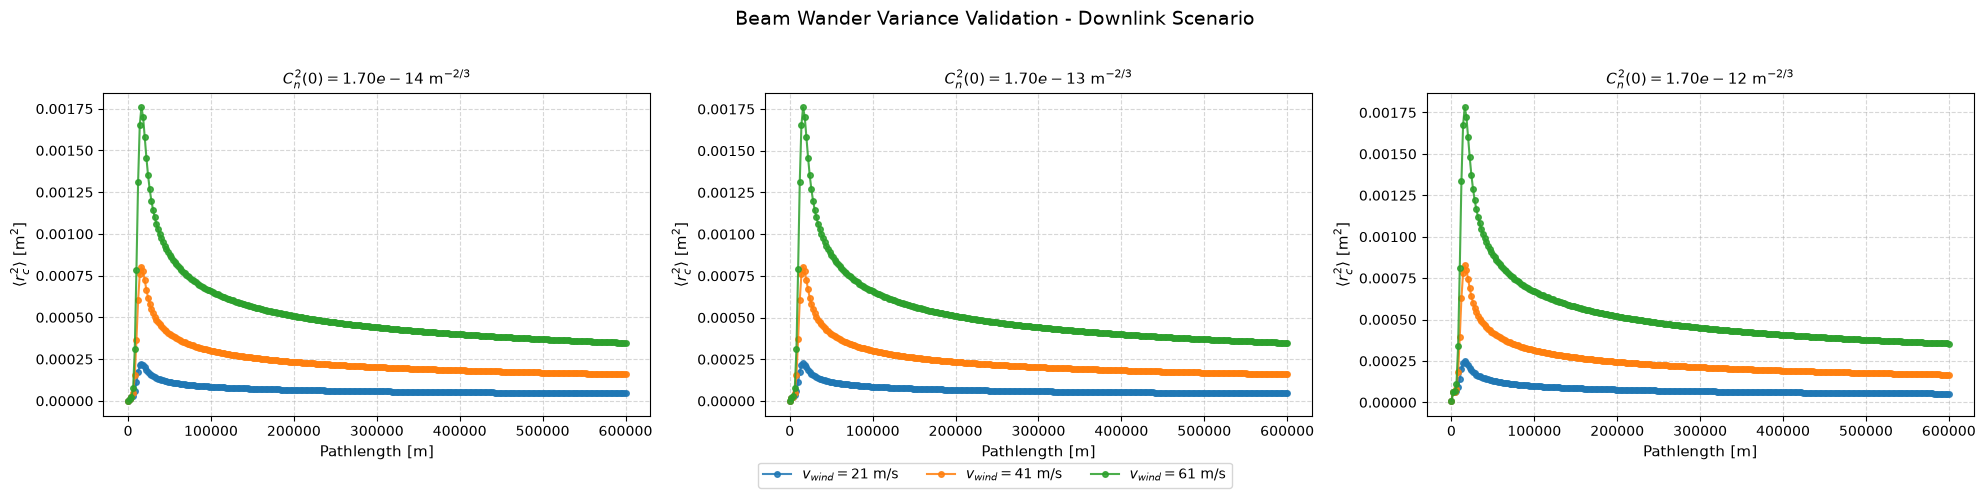

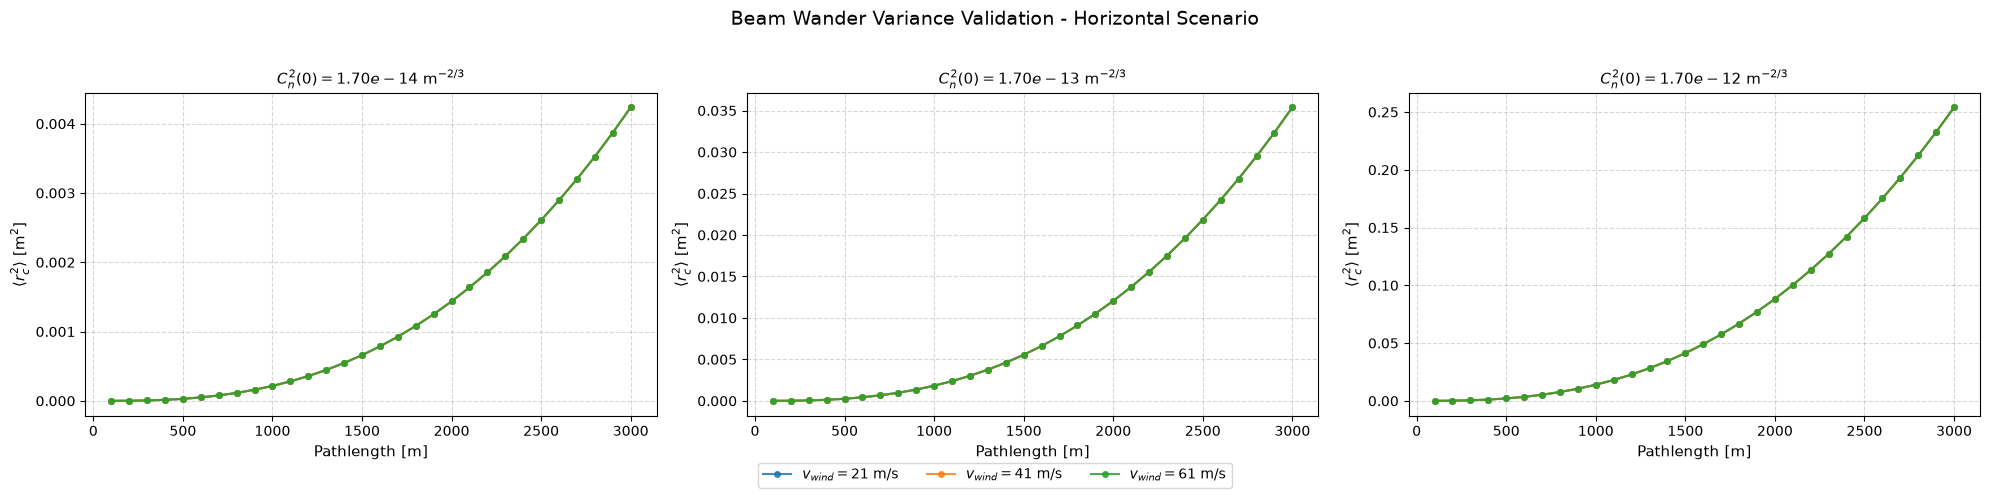

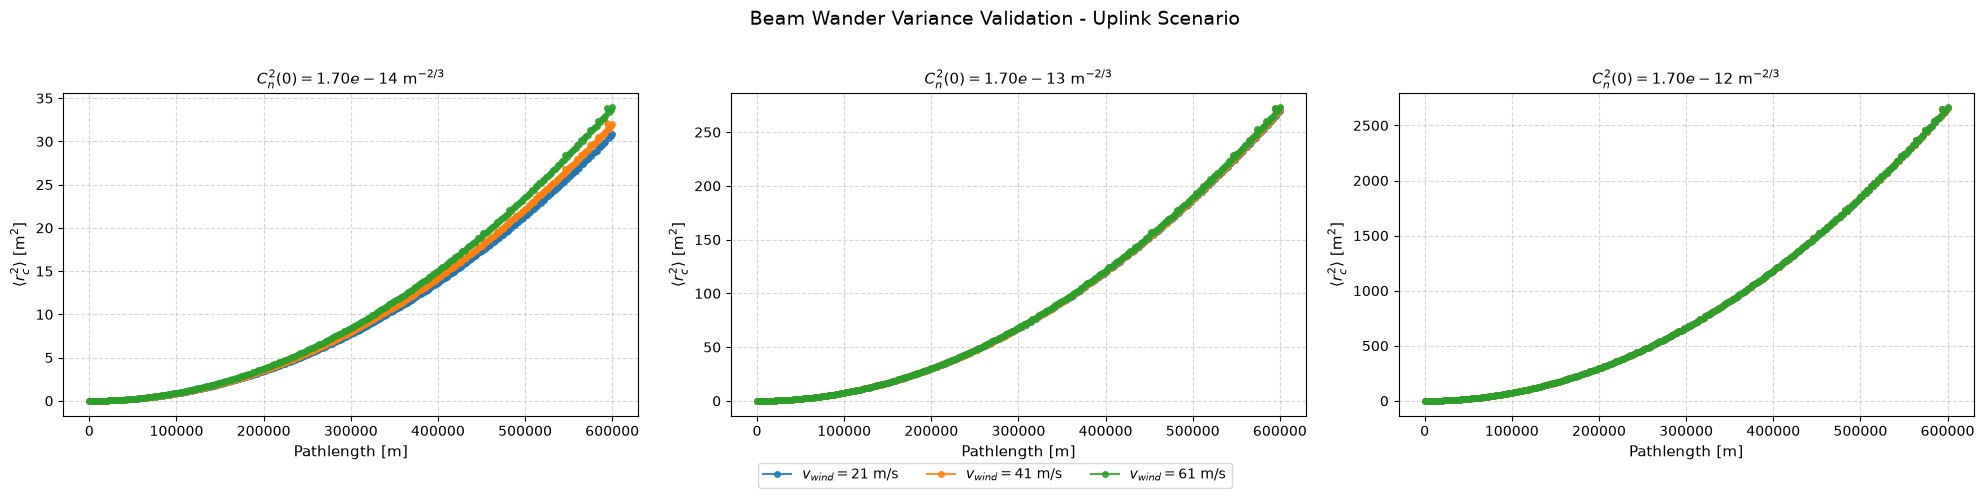

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

INPUT_FILE = "qdl_fso_beam_wander_validation.csv"
df = pd.read_csv(INPUT_FILE)

df = df.sort_values(["Cn20", "v_wind", "scenario", "pathlength"])

# ------------------------------------------------------------
# Get unique parameter values
# ------------------------------------------------------------

scenarios = sorted(df["scenario"].unique())
wind_speeds = sorted(df["v_wind"].unique())
cn20_values = sorted(df["Cn20"].unique())

# ------------------------------------------------------------
# Create one figure per Scenario (1 row x 3 columns for Cn20 values)
# ------------------------------------------------------------

for scenario in scenarios:

    scenario_df = df[df["scenario"] == scenario]

    if scenario_df.empty:
        continue

    # 3 rows x 1 column plot layout
    fig, axes = plt.subplots(
        nrows=1,
        ncols=3,
        figsize=(20, 5),
        sharex=True,
    )

    fig.suptitle(
        f"Beam Wander Variance Validation - {scenario} Scenario",
        fontsize=14,
        y=0.98,
    )

    # --------------------------------------------------------
    # Iterate through Cn20 values across the 3 rows
    # --------------------------------------------------------

    for i, cn20 in enumerate(cn20_values[:3]):  # Uses up to 3 Cn20 levels for 3 rows

        ax = axes[i]
        cn_df = scenario_df[scenario_df["Cn20"] == cn20]

        for wind in wind_speeds:

            case_df = cn_df[cn_df["v_wind"] == wind].sort_values("pathlength")

            if case_df.empty:
                continue

            label = f"$v_{{wind}} = {wind:g}$ m/s"

            # Plot Beam Wander Variance
            ax.plot(
                case_df["pathlength"],
                case_df["wander_var"],
                marker="o",
                markersize=4,
                linestyle="-",
                linewidth=1.5,
                alpha=0.85,
                label=label,
            )

        # Panel formatting
        ax.set_title(
            rf"$C_n^2(0) = {cn20:.2e}$ m$^{{-2/3}}$",
            fontsize=11,
            loc="center",
        )
        ax.set_ylabel(
            r"$\langle r_c^2 \rangle$ [m$^2$]",
            fontsize=11,
        )
        ax.grid(
            True,
            which="both",
            linestyle="--",
            alpha=0.5,
        )

        ax.set_xlabel(
            "Pathlength [m]",
            fontsize=11,
        )

    # --------------------------------------------------------
    # Shared legend
    # --------------------------------------------------------

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=len(wind_speeds),
        fontsize=10,
        bbox_to_anchor=(0.5, 0.01),
    )

    plt.tight_layout(rect=(0, 0.05, 1, 0.96))

    # plt.savefig(f"./figures/qdl_fso_beam_wander_{str.lower(scenario)}.pdf")
    plt.savefig(f"./figures/qdl_fso_beam_wander_{str.lower(scenario)}.png")

    plt.show()
    plt.close(fig)